# Predicting Building Energy Demand with Limited Data
### Xi Chen

## Introduction
This analysis uses the UCI Energy Efficiency dataset to predict heating load (Y1) from eight building characteristics. The aim is to develop an accurate prediction model and investigate whether the number of input features can be reduced without a substantial loss of performance.
The data were divided into 80% training data and 20% test data. Model development and feature selection were performed using the training data. The test data were reserved for the final evaluation.

In [72]:
# Load data
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
energy_efficiency = fetch_ucirepo(id=242) 
  
# data (as pandas dataframes) 
X = energy_efficiency.data.features 
y = energy_efficiency.data.targets['Y1'] 
  
# metadata 
print(energy_efficiency.metadata) 
  
# variable information 
print(energy_efficiency.variables) 


{'uci_id': 242, 'name': 'Energy Efficiency', 'repository_url': 'https://archive.ics.uci.edu/dataset/242/energy+efficiency', 'data_url': 'https://archive.ics.uci.edu/static/public/242/data.csv', 'abstract': 'This study looked into assessing the heating load and cooling load requirements of buildings (that is, energy efficiency) as a function of building parameters.', 'area': 'Computer Science', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 768, 'num_features': 8, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['Y1', 'Y2'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2012, 'last_updated': 'Mon Feb 26 2024', 'dataset_doi': '10.24432/C51307', 'creators': ['Athanasios Tsanas', 'Angeliki Xifara'], 'intro_paper': {'ID': 379, 'type': 'NATIVE', 'title': 'Accurate quantitative estimation of energy performance of residential buildings using statistical machine 

In [73]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFE
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [74]:
feature_names = {
    "X1": "Relative Compactness",
    "X2": "Surface Area",
    "X3": "Wall Area",
    "X4": "Roof Area",
    "X5": "Overall Height",
    "X6": "Orientation",
    "X7": "Glazing Area",
    "X8": "Glazing Area Distribution",
    "Y1": "Heating Load"
}

## 1.Multiple Linear Regression CV
Multiple linear regression was used as a baseline model. It provides a simple and interpretable reference against which more flexible models can be compared. Model performance was assessed using five-fold cross-validation with MAE, RMSE and $R^2$

In [88]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

cv_linear = cross_validate(
    linear_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

cv_mae_linear = -cv_linear["test_mae"].mean()
cv_rmse_linear = -cv_linear["test_rmse"].mean()
cv_r2_linear = cv_linear["test_r2"].mean()
cv_rmse_sd_linear = cv_linear["test_rmse"].std()

print("Multiple Linear Regression CV")
print(f"CV MAE: {cv_mae_linear:.3f}")
print(f"CV RMSE: {cv_rmse_linear:.3f}")
print(f"CV R²: {cv_r2_linear:.3f}")
print(f"CV RMSE SD: {cv_rmse_sd_linear:.3f}")

Multiple Linear Regression CV
CV MAE: 2.062
CV RMSE: 2.916
CV R²: 0.915
CV RMSE SD: 0.159


## 2.Eight-feature Random Forest CV
A random forest regression model was fitted using all eight available features. Random forest can model nonlinear relationships and interactions between predictors without requiring them to be specified in advance.

In [76]:
rf_8 = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=1
)

cv_8 = cross_validate(
    rf_8,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

cv_mae_8 = -cv_8["test_mae"].mean()
cv_rmse_8 = -cv_8["test_rmse"].mean()
cv_r2_8 = cv_8["test_r2"].mean()
cv_rmse_sd_8 = cv_8["test_rmse"].std()

print("Eight-feature Random Forest CV")
print(f"CV MAE: {cv_mae_8:.3f}")
print(f"CV RMSE: {cv_rmse_8:.3f}")
print(f"CV R²: {cv_r2_8:.3f}")
print(f"CV RMSE SD: {cv_rmse_sd_8:.3f}")

Eight-feature Random Forest CV
CV MAE: 0.345
CV RMSE: 0.520
CV R²: 0.997
CV RMSE SD: 0.025


The eight-feature random forest achieved lower cross-validation MAE and RMSE and a higher $R^2$ than multiple linear regression. Therefore, random forest was selected for the subsequent feature-reduction analysis.

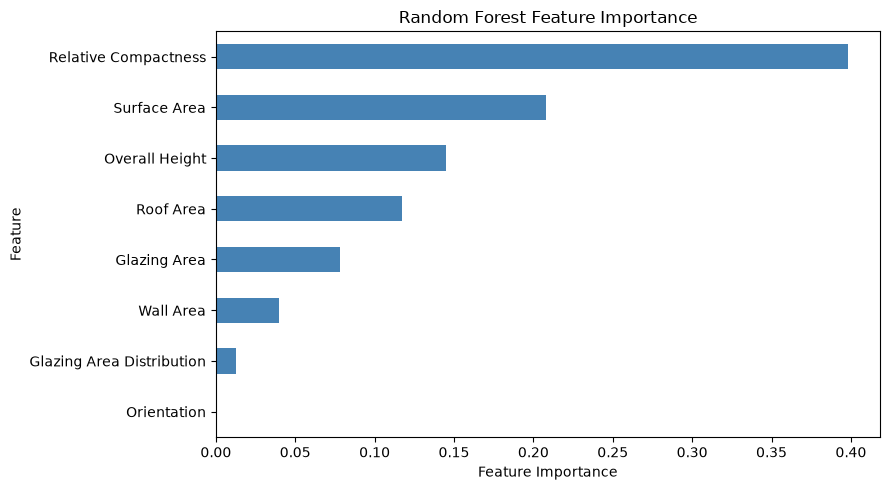

In [77]:
rf_8.fit(X_train, y_train)

feature_importance = pd.Series(
    rf_8.feature_importances_,
    index=X_train.columns
)

feature_importance_named = feature_importance.rename(
    index=feature_names
).sort_values()

plt.figure(figsize=(9, 5))

feature_importance_named.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [78]:
comparison_linear_rf = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "8-feature Random Forest"
    ],
    "Features": [8, 8],
    "CV MAE": [
        cv_mae_linear,
        cv_mae_8
    ],
    "CV RMSE": [
        cv_rmse_linear,
        cv_rmse_8
    ],
    "CV R²": [
        cv_r2_linear,
        cv_r2_8
    ],
    "RMSE SD": [
        cv_rmse_sd_linear,
        cv_rmse_sd_8
    ]
})

print(
    comparison_linear_rf
    .round(3)
    .to_string(index=False)
)

                     Model  Features  CV MAE  CV RMSE  CV R²  RMSE SD
Multiple Linear Regression         8   2.062    2.916  0.915    0.159
   8-feature Random Forest         8   0.345    0.520  0.997    0.025


## 3. Recursive Feature Elimination
### Five-feature Random Forest CV
Recursive Feature Elimination was used to reduce the number of predictors from eight to five. At each step, the least important feature was removed and the model was refitted. The procedure was performed using only the training data.

In [79]:
rfe_5 = RFE(
    estimator=RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=1
    ),
    n_features_to_select=5,
    step=1
)

rf_5_pipeline = Pipeline([
    ("rfe", rfe_5),
    (
        "model",
        RandomForestRegressor(
            n_estimators=300,
            random_state=42,
            n_jobs=1
        )
    )
])

cv_5 = cross_validate(
    rf_5_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

cv_mae_5 = -cv_5["test_mae"].mean()
cv_rmse_5 = -cv_5["test_rmse"].mean()
cv_r2_5 = cv_5["test_r2"].mean()
cv_rmse_sd_5 = cv_5["test_rmse"].std()

print("Five-feature Random Forest CV")
print(f"CV MAE: {cv_mae_5:.3f}")
print(f"CV RMSE: {cv_rmse_5:.3f}")
print(f"CV R²: {cv_r2_5:.3f}")
print(f"CV RMSE SD: {cv_rmse_sd_5:.3f}")

Five-feature Random Forest CV
CV MAE: 0.348
CV RMSE: 0.490
CV R²: 0.998
CV RMSE SD: 0.035


In [80]:
rfe_selector_5 = RFE(
    estimator=RandomForestRegressor(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    ),
    n_features_to_select=5,
    step=1
)

rfe_selector_5.fit(X_train, y_train)

features_5 = X_train.columns[
    rfe_selector_5.support_
].tolist()

features_5_named = [
    feature_names[feature]
    for feature in features_5
]

print("Five selected features:", features_5)
print("Five selected variables:", features_5_named)

Five selected features: ['X1', 'X2', 'X4', 'X5', 'X7']
Five selected variables: ['Relative Compactness', 'Surface Area', 'Roof Area', 'Overall Height', 'Glazing Area']


The five-feature model produced cross-validation results that were very similar to those of the eight-feature model. This indicates that three features could be removed without a substantial loss of predictive performance.

In [81]:
comparison_8_5 = pd.DataFrame({
    "Model": [
        "8-feature Random Forest",
        "5-feature Random Forest"
    ],
    "Features": [8, 5],
    "CV MAE": [
        cv_mae_8,
        cv_mae_5
    ],
    "CV RMSE": [
        cv_rmse_8,
        cv_rmse_5
    ],
    "CV R²": [
        cv_r2_8,
        cv_r2_5
    ],
    "RMSE SD": [
        cv_rmse_sd_8,
        cv_rmse_sd_5
    ]
})

print(
    comparison_8_5
    .round(3)
    .to_string(index=False)
)

                  Model  Features  CV MAE  CV RMSE  CV R²  RMSE SD
8-feature Random Forest         8   0.345     0.52  0.997    0.025
5-feature Random Forest         5   0.348     0.49  0.998    0.035


## 4.Three-feature Random Forest CV
A correlation matrix was created for the five features selected by RFE.

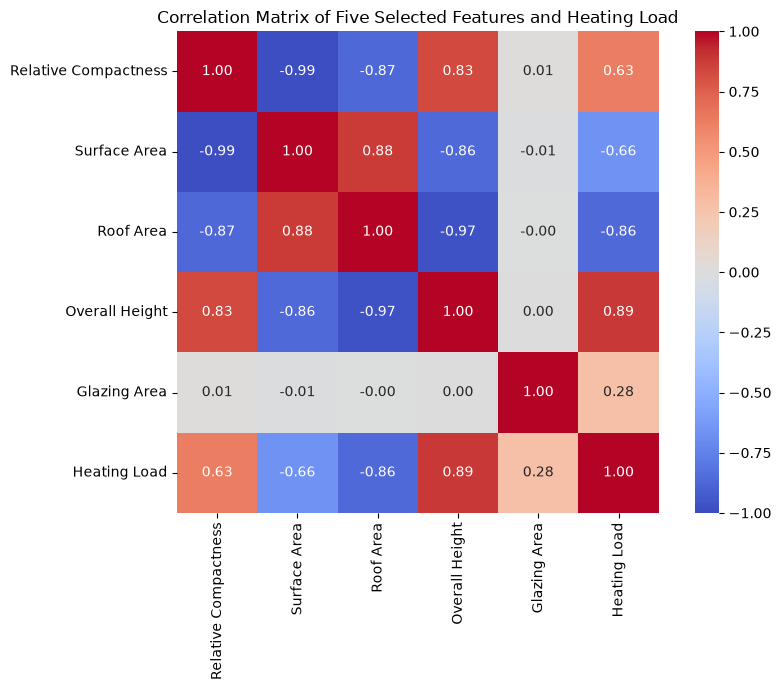

In [82]:
correlation_data_5 = pd.concat(
    [
        X_train[features_5],
        y_train.rename("Y1")
    ],
    axis=1
)

correlation_data_5 = correlation_data_5.rename(
    columns=feature_names
)

correlation_matrix_5 = correlation_data_5.corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    correlation_matrix_5,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title(
    "Correlation Matrix of Five Selected Features "
    "and Heating Load"
)

plt.tight_layout()
plt.show()

Based on the correlation structure, three candidate features were retained:
- Surface Area
- Overall Height
- Glazing Area
Surface Area and Overall Height describe important aspects of building geometry, while Glazing Area provides information that is less strongly correlated with the geometric variables.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2"
}
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])

cv_linear = cross_validate(
    linear_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

cv_mae_linear = -cv_linear["test_mae"].mean()
cv_rmse_linear = -cv_linear["test_rmse"].mean()
cv_r2_linear = cv_linear["test_r2"].mean()
cv_rmse_sd_linear = cv_linear["test_rmse"].std()

print("Multiple Linear Regression CV")
print(f"CV MAE: {cv_mae_linear:.3f}")
print(f"CV RMSE: {cv_rmse_linear:.3f}")
print(f"CV R²: {cv_r2_linear:.3f}")
print(f"CV RMSE SD: {cv_rmse_sd_linear:.3f}")

Multiple Linear Regression CV
CV MAE: 2.062
CV RMSE: 2.916
CV R²: 0.915
CV RMSE SD: 0.159


In [83]:
features_3 = ["X2", "X5", "X7"]

features_3_named = [
    feature_names[feature]
    for feature in features_3
]

print("Three candidate features:", features_3)
print("Three candidate variables:", features_3_named)

Three candidate features: ['X2', 'X5', 'X7']
Three candidate variables: ['Surface Area', 'Overall Height', 'Glazing Area']


In [84]:
rf_3 = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=1
)

cv_3 = cross_validate(
    rf_3,
    X_train[features_3],
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

cv_mae_3 = -cv_3["test_mae"].mean()
cv_rmse_3 = -cv_3["test_rmse"].mean()
cv_r2_3 = cv_3["test_r2"].mean()
cv_rmse_sd_3 = cv_3["test_rmse"].std()

print("Three-feature Random Forest CV")
print(f"CV MAE: {cv_mae_3:.3f}")
print(f"CV RMSE: {cv_rmse_3:.3f}")
print(f"CV R²: {cv_r2_3:.3f}")
print(f"CV RMSE SD: {cv_rmse_sd_3:.3f}")

Three-feature Random Forest CV
CV MAE: 0.348
CV RMSE: 0.490
CV R²: 0.998
CV RMSE SD: 0.034


In [85]:
cv_results = pd.DataFrame({
    "Model": [
        "Multiple Linear Regression",
        "8-feature Random Forest",
        "5-feature Random Forest",
        "3-feature Random Forest"
    ],
    "Features": [8, 8, 5, 3],
    "CV MAE": [
        cv_mae_linear,
        cv_mae_8,
        cv_mae_5,
        cv_mae_3
    ],
    "CV RMSE": [
        cv_rmse_linear,
        cv_rmse_8,
        cv_rmse_5,
        cv_rmse_3
    ],
    "CV R²": [
        cv_r2_linear,
        cv_r2_8,
        cv_r2_5,
        cv_r2_3
    ],
    "RMSE SD": [
        cv_rmse_sd_linear,
        cv_rmse_sd_8,
        cv_rmse_sd_5,
        cv_rmse_sd_3
    ]
})

print(
    cv_results
    .round(3)
    .to_string(index=False)
)

                     Model  Features  CV MAE  CV RMSE  CV R²  RMSE SD
Multiple Linear Regression         8   2.062    2.916  0.915    0.159
   8-feature Random Forest         8   0.345    0.520  0.997    0.025
   5-feature Random Forest         5   0.348    0.490  0.998    0.035
   3-feature Random Forest         3   0.348    0.490  0.998    0.034


## 5.Final Model Selection and Evaluation

In [86]:
rf_cv_results = cv_results[
    cv_results["Model"].str.contains(
        "Random Forest"
    )
].copy()

best_cv_rmse = rf_cv_results["CV RMSE"].min()
rmse_limit = best_cv_rmse * 1.10

eligible_models = rf_cv_results[
    rf_cv_results["CV RMSE"] <= rmse_limit
]

selected_row = eligible_models.sort_values(
    by="Features",
    ascending=True
).iloc[0]

selected_model_name = selected_row["Model"]
selected_number = int(selected_row["Features"])

print("Best Random Forest CV RMSE:", round(best_cv_rmse, 3))
print("10% RMSE limit:", round(rmse_limit, 3))
print("Selected model:", selected_model_name)

Best Random Forest CV RMSE: 0.49
10% RMSE limit: 0.539
Selected model: 3-feature Random Forest


Models with a cross-validation RMSE within 10% of the best result were considered acceptable. The model with the fewest features was then selected to balance accuracy and simplicity.The three-feature random forest met this criterion.

In [87]:
if selected_number == 8:
    final_features = X_train.columns.tolist()

elif selected_number == 5:
    final_features = features_5

else:
    final_features = features_3

final_feature_names = [
    feature_names[feature]
    for feature in final_features
]

final_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

final_model.fit(
    X_train[final_features],
    y_train
)

y_pred_final = final_model.predict(
    X_test[final_features]
)

final_mae = mean_absolute_error(
    y_test,
    y_pred_final
)

final_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_final
    )
)

final_r2 = r2_score(
    y_test,
    y_pred_final
)

print("Final Model:", selected_model_name)
print("Final Features:", final_feature_names)
print(f"Test MAE: {final_mae:.3f}")
print(f"Test RMSE: {final_rmse:.3f}")
print(f"Test R²: {final_r2:.3f}")

Final Model: 3-feature Random Forest
Final Features: ['Surface Area', 'Overall Height', 'Glazing Area']
Test MAE: 0.374
Test RMSE: 0.502
Test R²: 0.998


# 6.Conclusion
The final model was a three-feature random forest using Surface Area, Overall Height, and Glazing Area. On the test set, it achieved an MAE of 0.374, an RMSE of 0.502, and an $R^2$ of 0.998. This means that the model explained approximately 99.8% of the variation in heating load while maintaining low prediction errors. Reducing the number of features from eight to three simplified the model by 62.5% with only a small loss in predictive performance. These results suggest that the three selected building characteristics provide sufficient information for accurate heating-load prediction in this dataset.